In [42]:
import os
import gc
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from transformers import (
    AutoTokenizer,
    AutoModelForMultipleChoice,
    get_linear_schedule_with_warmup,
)

In [2]:
train = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
sample = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv')

**EDA**

In [3]:
print(train.columns)
train.head()
train.shape

Index(['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'], dtype='object')


(2000, 8)

In [4]:
train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [5]:
display(train.dtypes)

id         int64
prompt    object
A         object
B         object
C         object
D         object
E         object
answer    object
dtype: object

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [7]:
print(test.shape)
print(test.columns.tolist())

(500, 7)
['id', 'prompt', 'A', 'B', 'C', 'D', 'E']


In [8]:
display(test.head())

,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [9]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      500 non-null    int64 
 1   prompt  500 non-null    object
 2   A       500 non-null    object
 3   B       500 non-null    object
 4   C       500 non-null    object
 5   D       500 non-null    object
 6   E       500 non-null    object
dtypes: int64(1), object(6)
memory usage: 27.5+ KB


In [10]:
train.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [11]:
print(train.duplicated().sum())

print(train["prompt"].duplicated().sum())

0
242


In [12]:
duplicate_prompts = train[train["prompt"].duplicated(keep=False)]

display(
    duplicate_prompts[
        ["prompt", "A", "B", "C", "D", "E", "answer"]
    ].sort_values("prompt").head(10)
)

,prompt,A,B,C,D,E,answer
605,Choose the correct answer: What are permutatio...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,E
456,Choose the correct answer: What are permutatio...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,E
439,Choose the correct answer: What are permutatio...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,E
1464,Choose the correct answer: What are permutatio...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,E
42,Choose the correct answer: What are permutatio...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,E
484,Choose the correct answer: What are the four q...,"Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...","Holocrystalline, hypohyaline, hypercrystalline...","Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...",B
1621,Choose the correct answer: What are the four q...,"Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...","Holocrystalline, hypohyaline, hypercrystalline...","Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...",B
944,Choose the correct answer: What are the four q...,"Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...","Holocrystalline, hypohyaline, hypercrystalline...","Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...",B
778,Choose the correct answer: What is Lorentz sym...,Lorentz symmetry or Lorentz invariance is a pr...,Lorentz symmetry or Lorentz invariance is a me...,Lorentz symmetry or Lorentz invariance is a ph...,Lorentz symmetry or Lorentz invariance is a me...,Lorentz symmetry or Lorentz invariance is an e...,E
975,Choose the correct answer: What is Lorentz sym...,Lorentz symmetry or Lorentz invariance is a pr...,Lorentz symmetry or Lorentz invariance is a me...,Lorentz symmetry or Lorentz invariance is a ph...,Lorentz symmetry or Lorentz invariance is a me...,Lorentz symmetry or Lorentz invariance is an e...,E


In [13]:
train["answer"].value_counts()

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

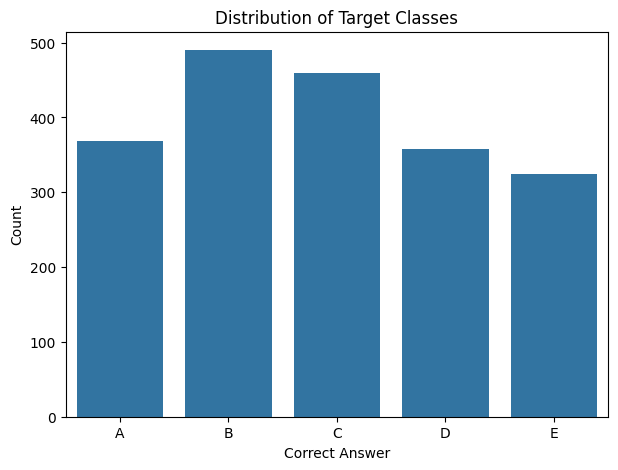

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

Percentage
answer
B    24.50
C    22.95
A    18.45
D    17.90
E    16.20
Name: proportion, dtype: float64


In [14]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=train,
    x="answer",
    order=["A","B","C","D","E"]
)

plt.title("Distribution of Target Classes")
plt.xlabel("Correct Answer")
plt.ylabel("Count")

plt.show()

print(train["answer"].value_counts())

print("\nPercentage")
print((train["answer"].value_counts(normalize=True)*100).round(2))

In [15]:
train["prompt_length"] = train["prompt"].str.split().str.len()

train["prompt_length"].describe()

count    2000.00000
mean       18.14650
std         6.78189
min         3.00000
25%        14.00000
50%        17.00000
75%        22.00000
max        51.00000
Name: prompt_length, dtype: float64

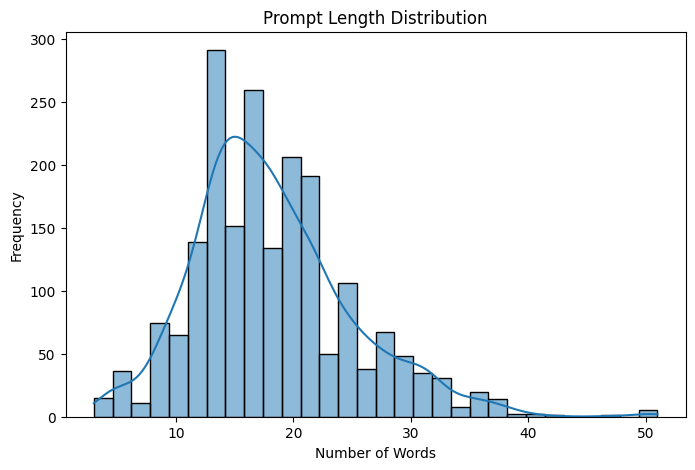

In [16]:
plt.figure(figsize=(8,5))

sns.histplot(
    train["prompt_length"],
    bins=30,
    kde=True
)

plt.title("Prompt Length Distribution")

plt.xlabel("Number of Words")

plt.ylabel("Frequency")

plt.show()

In [17]:
for option in ["A","B","C","D","E"]:
    train[f"{option}_length"] = train[option].str.split().str.len()

In [18]:
train[
    [
        "A_length",
        "B_length",
        "C_length",
        "D_length",
        "E_length"
    ]
].describe()

,A_length,B_length,C_length,D_length,E_length
count,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000
mean,26.146000,26.516000,26.54950,25.999500,26.187000
std,17.249651,18.653893,17.20987,17.098909,17.852658
min,1.000000,1.000000,1.00000,1.000000,1.000000
25%,13.000000,12.000000,14.75000,15.000000,13.000000
50%,22.000000,23.000000,24.00000,22.000000,23.000000
75%,37.000000,36.000000,36.00000,36.000000,36.000000
max,81.000000,118.000000,82.00000,78.000000,105.000000


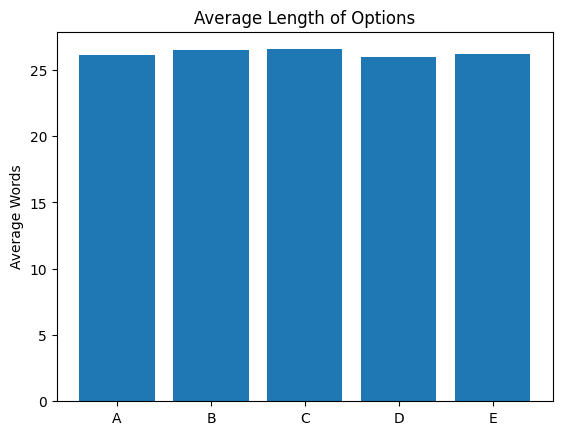

In [19]:
avg_lengths = []

for option in ["A","B","C","D","E"]:
    avg_lengths.append(train[f"{option}_length"].mean())

plt.bar(
    ["A","B","C","D","E"],
    avg_lengths
)

plt.ylabel("Average Words")

plt.title("Average Length of Options")

plt.show()

In [20]:
words = []

for sentence in train["prompt"]:

    words.extend(sentence.lower().split())

print("Vocabulary Size:", len(set(words)))

Vocabulary Size: 931


In [21]:
counter = Counter(words)

counter.most_common(20)

[('the', 5528),
 ('is', 1986),
 ('what', 1809),
 ('of', 1514),
 ('correct', 893),
 ('following', 746),
 ('in', 714),
 ('answer:', 608),
 ('option:', 608),
 ('and', 448),
 ('from', 442),
 ('a', 425),
 ('on', 424),
 ('which', 399),
 ('based', 397),
 ('among', 388),
 ('listed', 388),
 ('options.', 388),
 ('given', 376),
 ('context.', 376)]

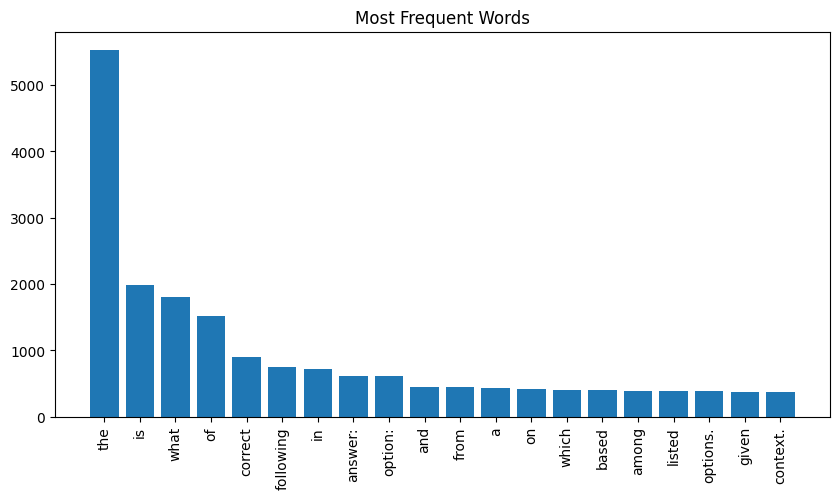

In [22]:
common = counter.most_common(20)

word = [x[0] for x in common]
count = [x[1] for x in common]

plt.figure(figsize=(10,5))

plt.bar(word,count)

plt.xticks(rotation=90)

plt.title("Most Frequent Words")

plt.show()

In [23]:
train.loc[
    train["prompt_length"].idxmax(),
    "prompt"
]

'Select the most accurate option: What is one of the examples of the models proposed by cosmologists and theoretical physicists without the cosmological or Copernican principles that can be used to address specific issues in the Lambda-CDM model and distinguish between current models and other possible models? among the listed options.'

In [24]:
train.loc[
    train["prompt_length"].idxmin(),
    "prompt"
]

'What is emissivity?'

In [25]:
MODEL_NAME = "microsoft/deberta-v3-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

MAX_LENGTH = 512

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

In [26]:
class TestDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=512):
        self.df = df
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        prompt = row["prompt"]

        first_sentences = [prompt] * 5
        second_sentences = [
            row["A"],
            row["B"],
            row["C"],
            row["D"],
            row["E"],
        ]

        enc = self.tokenizer(
            first_sentences,
            second_sentences,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": enc["input_ids"],
            "attention_mask": enc["attention_mask"]
        }

In [27]:
test_dataset = TestDataset(test, tokenizer, MAX_LENGTH)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False
)

In [28]:
!find /kaggle/input/notebooks -name "model.safetensors"

/kaggle/input/notebooks/arc24ade/roberta/models/fold_0/model.safetensors
/kaggle/input/notebooks/arc24ade/roberta/models/fold_4/model.safetensors
/kaggle/input/notebooks/arc24ade/roberta/models/fold_1/model.safetensors
/kaggle/input/notebooks/arc24ade/roberta/models/fold_3/model.safetensors
/kaggle/input/notebooks/arc24ade/roberta/models/fold_2/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_0/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_4/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_1/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_3/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_2/model.safetensors


In [29]:
!find /kaggle/input/notebooks -name "model.safetensors"

/kaggle/input/notebooks/arc24ade/roberta/models/fold_0/model.safetensors
/kaggle/input/notebooks/arc24ade/roberta/models/fold_4/model.safetensors
/kaggle/input/notebooks/arc24ade/roberta/models/fold_1/model.safetensors
/kaggle/input/notebooks/arc24ade/roberta/models/fold_3/model.safetensors
/kaggle/input/notebooks/arc24ade/roberta/models/fold_2/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_0/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_4/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_1/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_3/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_2/model.safetensors


In [30]:
!find /kaggle/input/notebooks -path "*deberta*" -name "model.safetensors"

/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_0/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_4/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_1/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_3/model.safetensors
/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_2/model.safetensors


In [31]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [32]:
DATA_PATH = "/kaggle/input/competitions/smart-mcq-solver-challenge"

test = pd.read_csv(f"{DATA_PATH}/test.csv")

test.head()

,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [33]:
import os

DEBERTA_PATH = "/kaggle/input/notebooks/arc24ade/deberta-model/models"

for i in range(5):
    print(f"Fold {i}")
    print(os.listdir(f"{DEBERTA_PATH}/fold_{i}"))
    print("-"*40)

Fold 0
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------
Fold 1
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------
Fold 2
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------
Fold 3
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------
Fold 4
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------


In [34]:
ROBERTA_PATH = "/kaggle/input/notebooks/arc24ade/roberta/models"

for i in range(5):
    print(f"Fold {i}")
    print(os.listdir(f"{ROBERTA_PATH}/fold_{i}"))
    print("-"*40)

Fold 0
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------
Fold 1
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------
Fold 2
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------
Fold 3
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------
Fold 4
['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
----------------------------------------


In [35]:
from torch.utils.data import Dataset

class MCQDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=512):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        prompt = row["prompt"]

        first_sentences = [prompt] * 5
        second_sentences = [
            row["A"],
            row["B"],
            row["C"],
            row["D"],
            row["E"],
        ]

        encoding = self.tokenizer(
            first_sentences,
            second_sentences,
            truncation=True,
            max_length=self.max_length,
            padding="max_length",
            return_tensors="pt",
        )

        return {
            "input_ids": encoding["input_ids"],
            "attention_mask": encoding["attention_mask"],
        }

In [36]:
import numpy as np
import torch

def predict_model(model, dataloader):
    model.eval()

    predictions = []

    with torch.no_grad():
        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits

            probs = torch.softmax(logits, dim=1)

            predictions.append(probs.cpu().numpy())

    return np.concatenate(predictions)

In [37]:
from transformers import AutoTokenizer

deberta_tokenizer = AutoTokenizer.from_pretrained(
    "microsoft/deberta-v3-base"
)

roberta_tokenizer = AutoTokenizer.from_pretrained(
    "roberta-base"
)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [38]:
from torch.utils.data import DataLoader

deberta_dataset = MCQDataset(test, deberta_tokenizer)
roberta_dataset = MCQDataset(test, roberta_tokenizer)

deberta_loader = DataLoader(
    deberta_dataset,
    batch_size=8,
    shuffle=False
)

roberta_loader = DataLoader(
    roberta_dataset,
    batch_size=8,
    shuffle=False
)

In [39]:
model = AutoModelForMultipleChoice.from_pretrained(
    "/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_0"
)

model.to(device)

print("Loaded successfully!")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loaded successfully!


In [40]:
label_map = np.array(["A", "B", "C", "D", "E"])

In [43]:
deberta_preds = np.zeros((len(test), 5))

for fold in range(5):

    print(f"DeBERTa Fold {fold}")

    model = AutoModelForMultipleChoice.from_pretrained(
        f"/kaggle/input/notebooks/arc24ade/deberta-model/models/fold_{fold}"
    )

    model.to(device)

    deberta_preds += predict_model(model, deberta_loader)

    del model
    gc.collect()
    torch.cuda.empty_cache()

deberta_preds /= 5

DeBERTa Fold 0


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DeBERTa Fold 1


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DeBERTa Fold 2


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DeBERTa Fold 3


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DeBERTa Fold 4


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

In [44]:
roberta_preds = np.zeros((len(test), 5))

for fold in range(5):

    print(f"RoBERTa Fold {fold}")

    model = AutoModelForMultipleChoice.from_pretrained(
        f"/kaggle/input/notebooks/arc24ade/roberta/models/fold_{fold}"
    )

    model.to(device)

    roberta_preds += predict_model(model, roberta_loader)

    del model
    gc.collect()
    torch.cuda.empty_cache()

roberta_preds /= 5

RoBERTa Fold 0


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RoBERTa Fold 1


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RoBERTa Fold 2


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RoBERTa Fold 3


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RoBERTa Fold 4


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [45]:
top3 = np.argsort(-roberta_preds, axis=1)[:, :3]

predictions = [
    " ".join(label_map[idx])
    for idx in top3
]

submission = pd.DataFrame({
    "ID": test["id"],
    "Prediction": predictions
})

submission.to_csv("submission.csv", index=False)

In [ ]:
import json
import pickle
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import re
from torch.utils.data import Dataset, DataLoader

In [ ]:
MODEL_DIR = "/kaggle/input/notebooks/arc24ade/bilstm-model/models"

with open(f"{MODEL_DIR}/vocab.json", "r") as f:
    vocab = json.load(f)

with open(f"{MODEL_DIR}/label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

In [ ]:
def tokenize(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r"[^a-z0-9 ]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.split()


def numericalize(text):

    ids = []

    for token in tokenize(text):
        ids.append(vocab.get(token, vocab["<UNK>"]))

    ids = ids[:CFG.MAX_LEN]

    if len(ids) < CFG.MAX_LEN:
        ids += [0] * (CFG.MAX_LEN - len(ids))

    return ids

In [ ]:
class TestDataset(Dataset):

    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        prompt = str(row["prompt"])

        choices = []

        for option in ["A","B","C","D","E"]:

            text = prompt + " " + str(row[option])

            choices.append(
                numericalize(text)
            )

        return torch.tensor(
            choices,
            dtype=torch.long
        )

In [ ]:
class TestDataset(Dataset):

    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        prompt = str(row["prompt"])

        choices = []

        for option in ["A","B","C","D","E"]:

            text = prompt + " " + str(row[option])

            choices.append(
                numericalize(text)
            )

        return torch.tensor(
            choices,
            dtype=torch.long
        )

In [ ]:
test = pd.read_csv(CFG.TEST_PATH)

test_dataset = TestDataset(test)

test_loader = DataLoader(
    test_dataset,
    batch_size=CFG.BATCH_SIZE,
    shuffle=False
)

bilstm_preds = []

with torch.no_grad():

    for choices in test_loader:

        choices = choices.to(CFG.DEVICE)

        logits = model(choices)

        probs = F.softmax(logits, dim=1)

        bilstm_preds.append(
            probs.cpu().numpy()
        )

bilstm_preds = np.concatenate(
    bilstm_preds,
    axis=0
)

print(bilstm_preds.shape)

In [ ]:
# Read test data
test = pd.read_csv(CFG.TEST_PATH)

test_dataset = TestDataset(test)

test_loader = DataLoader(
    test_dataset,
    batch_size=CFG.BATCH_SIZE,
    shuffle=False
)

bilstm_preds = []

model.eval()

with torch.no_grad():

    for choices in test_loader:

        choices = choices.to(CFG.DEVICE)

        logits = model(choices)

        probs = F.softmax(logits, dim=1)

        bilstm_preds.append(probs.cpu().numpy())

bilstm_preds = np.concatenate(bilstm_preds, axis=0)

print(bilstm_preds.shape)
print(bilstm_preds[:5])   